In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

In [35]:
#SVM Functions

KERNELS = ["linear", "poly", "rbf", "sigmoid"]
# How data is transformed from lower to higher dimmension form
# Linear - x*y , Polynomial - (x*y +c)^d ,
# Radial Bias - maps data into an infinite dimmension , Sigmoid - Hyperbolic tangent function

#score output of validation set
def scores(model, Xa, ya):
    p = model.predict(Xa)
    return {"Accuracy":  sklearn.metrics.accuracy_score(ya, p),
            "Precision": sklearn.metrics.precision_score(ya, p, zero_division=0),
            "Recall":    sklearn.metrics.recall_score(ya, p),
            "F1":        sklearn.metrics.f1_score(ya, p)}

# Regularization so R2/RMSE/MAE can be displayed properly
def to_price(pred_s, y_scaler):
    #Standardized predictions -> dollars
    return y_scaler.inverse_transform(np.asarray(pred_s).reshape(-1, 1)).ravel()
def reg_scores(pred_s, y_true, y_scaler):
    #R2 / RMSE / MAE in dollars, from standardized predictions
    p = to_price(pred_s, y_scaler)
    return {"R2":   sklearn.metrics.r2_score(y_true, p),
            "RMSE": sklearn.metrics.mean_squared_error(y_true, p) ** 0.5,
            "MAE":  sklearn.metrics.mean_absolute_error(y_true, p)}


In [36]:
#Datasetinput Problem 1
url = 'https://raw.githubusercontent.com/HamedTabkhi/Intro-to-ML/main/Dataset/Cancer.csv'
dc = pd.DataFrame(pd.read_csv(url))
dc = dc.drop(["id", "Unnamed: 32"], axis=1)
dc = dc[(dc != 0).all(axis=1)]


X = dc.drop(columns="diagnosis")
y = (dc["diagnosis"] == "M").astype(int).values

X_train, X_val, y_train, y_val = sklearn.model_selection.train_test_split(X, y, test_size=0.2, random_state=163)
scaler = sklearn.preprocessing.StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

print("Training rows:", len(y_train), "| Validation rows:", len(y_val))

Training rows: 444 | Validation rows: 112


,Accuracy,Precision,Recall,F1,Train acc,# support vectors
linear,0.9911,1.0000,0.9787,0.9892,0.9865,39.0
poly,0.8482,1.0000,0.6383,0.7792,0.9122,143.0
rbf,1.0000,1.0000,1.0000,1.0000,0.9797,108.0
sigmoid,0.9554,0.9565,0.9362,0.9462,0.9459,67.0


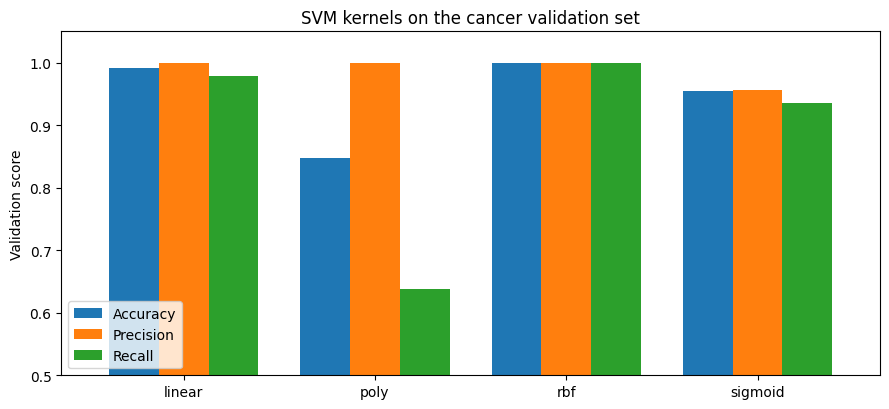

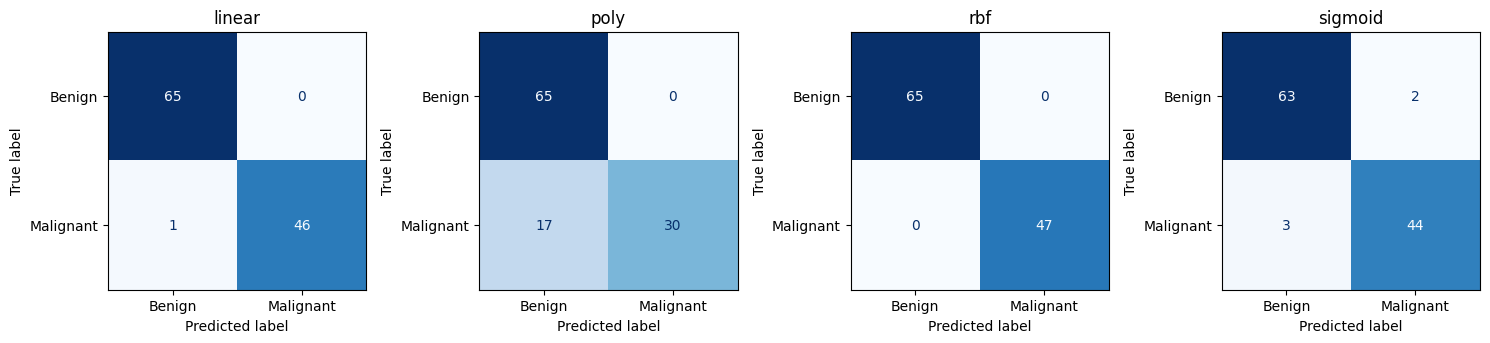

In [37]:
#Problem 1 SVM Cancer for each kernel

models, rows = {}, []

for k in KERNELS:
    m = sklearn.svm.SVC(kernel=k, C=1.0, gamma="scale", degree=3, random_state=42).fit(X_train, y_train)
    models[k] = m

    r = scores(m, X_val, y_val)
    r["Train acc"] = m.score(X_train, y_train)
    r["# support vectors"] = int(m.n_support_.sum())
    rows.append(pd.Series(r, name=k))


res1 = pd.DataFrame(rows)
display(res1.round(4))

# bar chart of accuracy / precision / recall
fig, ax = plt.subplots(figsize=(9, 4.2))
res1[["Accuracy", "Precision", "Recall"]].plot.bar(ax=ax, rot=0, width=0.78)
ax.set_ylim(0.5, 1.05); ax.set_ylabel("Validation score")
ax.set_title("SVM kernels on the cancer validation set"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

# confusion matrix per kernel
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, k in zip(axes, KERNELS):
    cm = sklearn.metrics.confusion_matrix(y_val, models[k].predict(X_val))
    sklearn.metrics.ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(k); ax.grid(False)
plt.tight_layout(); plt.show()



In [38]:
#Problem 2 Housing Dataset Input
url = 'https://raw.githubusercontent.com/HamedTabkhi/Intro-to-ML/main/Dataset/Housing.csv'
dh = pd.DataFrame(pd.read_csv(url))
cols = ["area","bedrooms","bathrooms","stories","mainroad","guestroom","basement",
        "hotwaterheating","airconditioning","parking","prefarea"]

Xh = dh[cols].copy()
for c in ["mainroad","guestroom","basement","hotwaterheating","airconditioning","prefarea"]:
    Xh[c] = (Xh[c] == "yes").astype(int)
yh = dh["price"].values.astype(float)

Xh_train, Xh_val, yh_train, yh_val = sklearn.model_selection.train_test_split(Xh.values.astype(float), yh, test_size=0.2, random_state=163)
scaler_x = sklearn.preprocessing.StandardScaler().fit(Xh_train)
scaler_y = sklearn.preprocessing.StandardScaler().fit(yh_train.reshape(-1, 1))
Xs_train, Xs_val = scaler_x.transform(Xh_train), scaler_x.transform(Xh_val)
ys_train = scaler_y.transform(yh_train.reshape(-1, 1)).ravel()

print("Rows:", len(yh), "| train:", len(yh_train), "| test:", len(yh_val))

Rows: 545 | train: 436 | test: 109


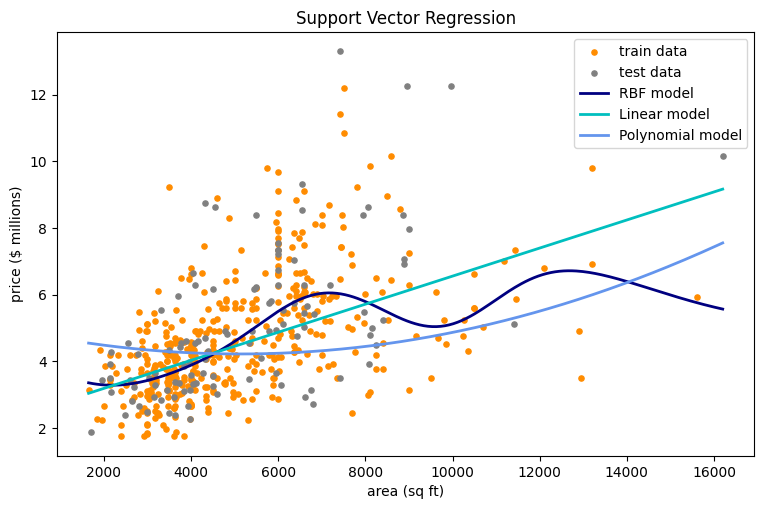

RBF test R2 (area only): 0.223
Linear test R2 (area only): 0.294
Polynomial test R2 (area only): -0.032


In [39]:
#Problem 2 SVR Regression for Housing Data

h_train = Xh_train[:, 0].reshape(-1, 1);  h_val = Xh_val[:, 0].reshape(-1, 1)   # area is column 0
scaler_h = sklearn.preprocessing.StandardScaler().fit(h_train)

#scaled SVR ran with sklearn
svr_rbf  = sklearn.svm.SVR(kernel='rbf',    C=1, gamma=1.0)
svr_lin  = sklearn.svm.SVR(kernel='linear', C=1)
svr_poly = sklearn.svm.SVR(kernel='poly',   C=1, degree=2)

#reformatted
h_line = np.linspace(Xh[:, 0].min() if hasattr(Xh, "columns") is False else Xh["area"].min(),Xh["area"].max(), 300).reshape(-1, 1)             # smooth x-axis for the curves
y_rbf  = to_price(svr_rbf.fit(scaler_h.transform(h_train),  ys_train).predict(scaler_h.transform(h_line)), scaler_y) / 1e6
y_lin  = to_price(svr_lin.fit(scaler_h.transform(h_train),  ys_train).predict(scaler_h.transform(h_line)), scaler_y) / 1e6
y_poly = to_price(svr_poly.fit(scaler_h.transform(h_train), ys_train).predict(scaler_h.transform(h_line)), scaler_y) / 1e6

#graph setup as seen on the github
lw = 2
plt.figure(figsize=(9, 5.5))
plt.scatter(h_train, yh_train / 1e6, color='darkorange', s=14, label='train data')
plt.scatter(h_val, yh_val / 1e6, color='gray', s=14, label='test data')
plt.plot(h_line, y_rbf,  color='navy',           lw=lw, label='RBF model')
plt.plot(h_line, y_lin,  color='c',              lw=lw, label='Linear model')
plt.plot(h_line, y_poly, color='cornflowerblue', lw=lw, label='Polynomial model')
plt.xlabel('area (sq ft)'); plt.ylabel('price ($ millions)')
plt.title('Support Vector Regression')
plt.legend(); plt.show()

for name, m in [("RBF", svr_rbf), ("Linear", svr_lin), ("Polynomial", svr_poly)]:
    print(name, "test R2 (area only): %.3f" % reg_scores(m.predict(scaler_h.transform(h_val)), yh_val, scaler_y)["R2"])